# 03 — Bayesian hyperparameter optimisation (M2)

Optuna **TPE** on LightGBM (the model selected in `02_models`). This notebook only reads the saved outputs of `scripts/tune_optuna.py` and `scripts/export_model.py`.

Reproduce:
```
python scripts/tune_optuna.py --model lgbm --trials 50 --timeout-min 40 --folds 3 --obs-every 4 --tag v1
python scripts/export_model.py --model lgbm --tag tuned --params-json results/m2/optuna_best_params_v1.json
```

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = ROOT / "results" / "m2"
P = R / "plots"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)
def show(name, width=900):
    display(Image(filename=str(P / name), width=width))

## 1. Study settings and best trial

In [2]:
best = json.loads((R / "optuna_best_params_v1.json").read_text())
{k: best[k] for k in ["model", "objective", "sampler", "pruner", "folds", "obs_every", "n_trials", "n_complete",
                      "n_pruned", "wall_time_s", "best_trial", "best_value", "cv_top1", "cv_logloss", "cv_macro_f1",
                      "label_source"]}

{'model': 'lgbm',
 'objective': 'mean GroupKFold obs top1',
 'sampler': 'TPESampler(seed=42)',
 'pruner': 'MedianPruner(n_startup_trials=5, n_warmup_steps=1)',
 'folds': 3,
 'obs_every': 4,
 'n_trials': 50,
 'n_complete': 27,
 'n_pruned': 23,
 'wall_time_s': 1354.1941164000018,
 'best_trial': 41,
 'best_value': 0.918597990856224,
 'cv_top1': 0.918597990856224,
 'cv_logloss': 0.0403812475549267,
 'cv_macro_f1': 0.9511865563878418,
 'label_source': 'train=M3_alignment; student_test=M3_alignment'}

### Best hyperparameters (full set passed to LightGBM, incl. fixed values)

In [3]:
pd.Series(best["params"], name="value").to_frame()

,value
n_estimators,2000.0000
num_leaves,185.0000
learning_rate,0.0265
min_child_samples,19.0000
colsample_bytree,0.8395
subsample,0.7446
subsample_freq,1.0000
reg_alpha,0.0019
reg_lambda,0.0033


## 2. Search space (defined in `scripts/tune_optuna.py::space`)

In [4]:
pd.DataFrame([
    ("num_leaves", "int 15–255", "log"), ("learning_rate", "float 0.01–0.2", "log"),
    ("min_child_samples", "int 10–200", "log"), ("colsample_bytree", "float 0.5–1.0", "linear"),
    ("subsample", "float 0.5–1.0 (subsample_freq=1)", "linear"), ("reg_alpha", "float 1e-3–10", "log"),
    ("reg_lambda", "float 1e-3–10", "log"), ("n_estimators", "fixed 2000, early stopping 30 rounds on inner trip split", "—"),
], columns=["parameter", "range", "scale"])

,parameter,range,scale
0,num_leaves,int 15–255,log
1,learning_rate,float 0.01–0.2,log
2,min_child_samples,int 10–200,log
3,colsample_bytree,float 0.5–1.0,linear
4,subsample,float 0.5–1.0 (subsample_freq=1),linear
5,reg_alpha,float 1e-3–10,log
6,reg_lambda,float 1e-3–10,log
7,n_estimators,"fixed 2000, early stopping 30 rounds on inner ...",—


## 3. All trials

In [5]:
t = pd.read_csv(R / "optuna_trials_v1.csv")
display(t["state"].value_counts().to_frame("trials"))
cols = ["number", "value", "state"] + [c for c in t.columns if c.startswith("params_")] + \
       [c for c in t.columns if c.startswith("user_attrs_")]
t[cols].sort_values("value", ascending=False).head(10)

,trials
state,
COMPLETE,27
PRUNED,23


,number,value,state,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_num_leaves,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_cv_logloss,user_attrs_cv_macro_f1,user_attrs_cv_top1,user_attrs_cv_top1_std,user_attrs_fit_time_s
41,41,0.9186,COMPLETE,0.8395,0.0265,19,185,0.0019,0.0033,0.7446,0.0404,0.9512,0.9186,0.0110,17.7601
5,5,0.9186,COMPLETE,0.8421,0.0249,13,147,0.0031,0.0957,0.7201,0.0401,0.9512,0.9186,0.0110,10.9125
45,45,0.9181,COMPLETE,0.8561,0.0186,20,218,0.0018,0.0033,0.6314,0.0407,0.9508,0.9181,0.0107,50.5831
14,14,0.9181,COMPLETE,0.8093,0.0526,17,100,0.0023,0.0044,0.7689,0.0403,0.9508,0.9181,0.0111,16.1660
15,15,0.9180,COMPLETE,0.8797,0.0171,11,117,0.0055,0.0482,0.7949,0.0401,0.9508,0.9180,0.0097,42.6607
46,46,0.9179,COMPLETE,0.8448,0.0254,11,195,0.0016,0.0064,0.7221,0.0405,0.9506,0.9179,0.0109,36.6833
49,49,0.9179,COMPLETE,0.8962,0.0150,21,254,0.0027,0.0023,0.6815,0.0411,0.9505,0.9179,0.0097,67.1857
44,44,0.9178,COMPLETE,0.8238,0.0326,20,173,0.0052,0.0033,0.6323,0.0407,0.9508,0.9178,0.0110,28.6505
13,13,0.9177,COMPLETE,0.8135,0.0408,14,215,0.0013,0.0038,0.6837,0.0411,0.9509,0.9177,0.0108,29.7823
37,37,0.9177,COMPLETE,0.7913,0.0387,13,167,0.0019,0.0663,0.7467,0.0404,0.9511,0.9177,0.0101,19.1177


### Objective vs the most important parameters (complete trials, from the CSV)

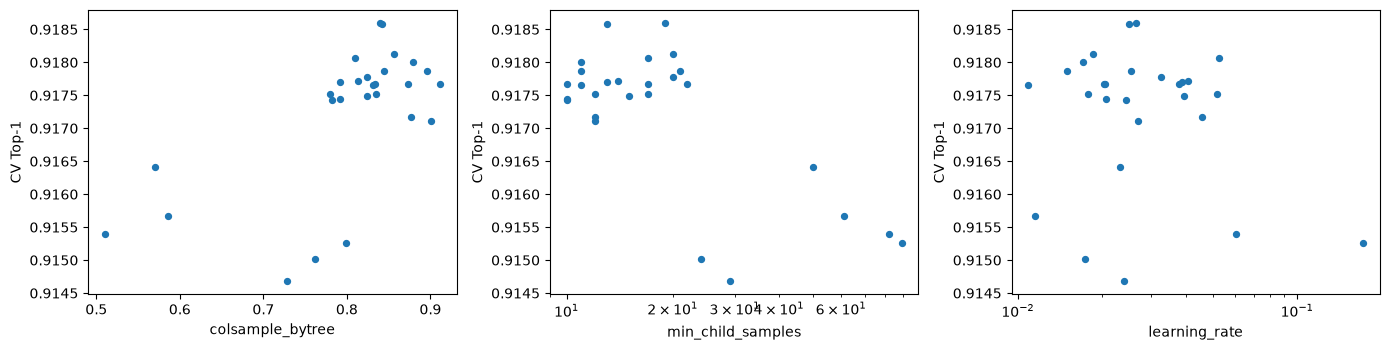

In [6]:
c = t[t["state"] == "COMPLETE"]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, p in zip(axs, ["params_colsample_bytree", "params_min_child_samples", "params_learning_rate"]):
    ax.scatter(c[p], c["value"], s=18)
    ax.set_xlabel(p.replace("params_", "")); ax.set_ylabel("CV Top-1")
    if p != "params_colsample_bytree":
        ax.set_xscale("log")
fig.tight_layout()

## 4. Optimisation history and parameter importance (Optuna, matplotlib)

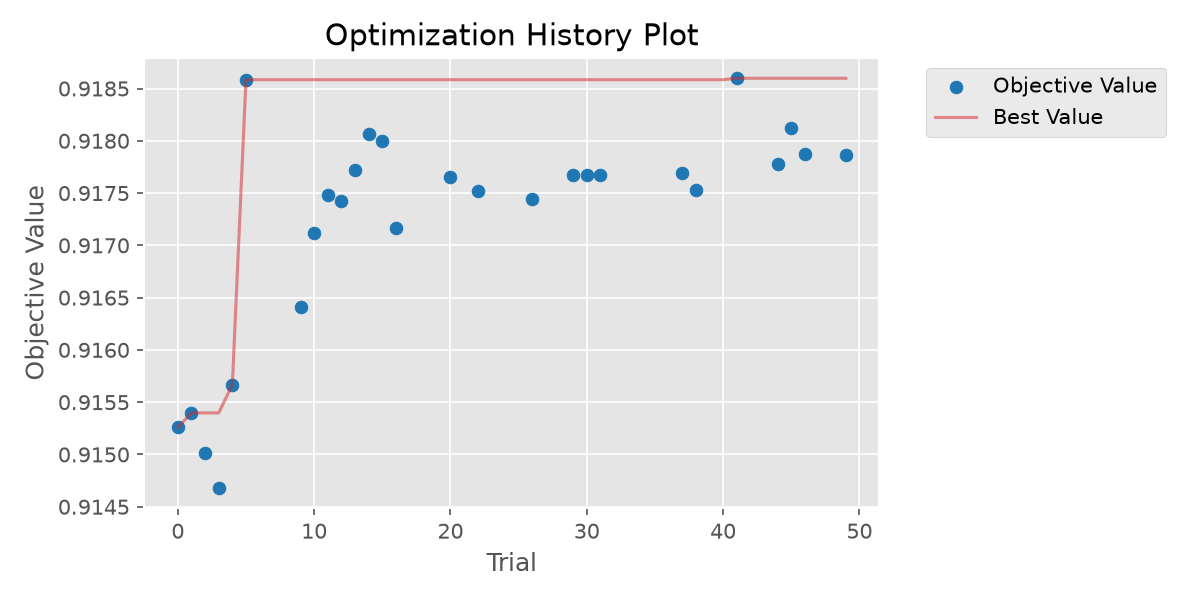

In [7]:
show("optuna_history_v1.png", 850)

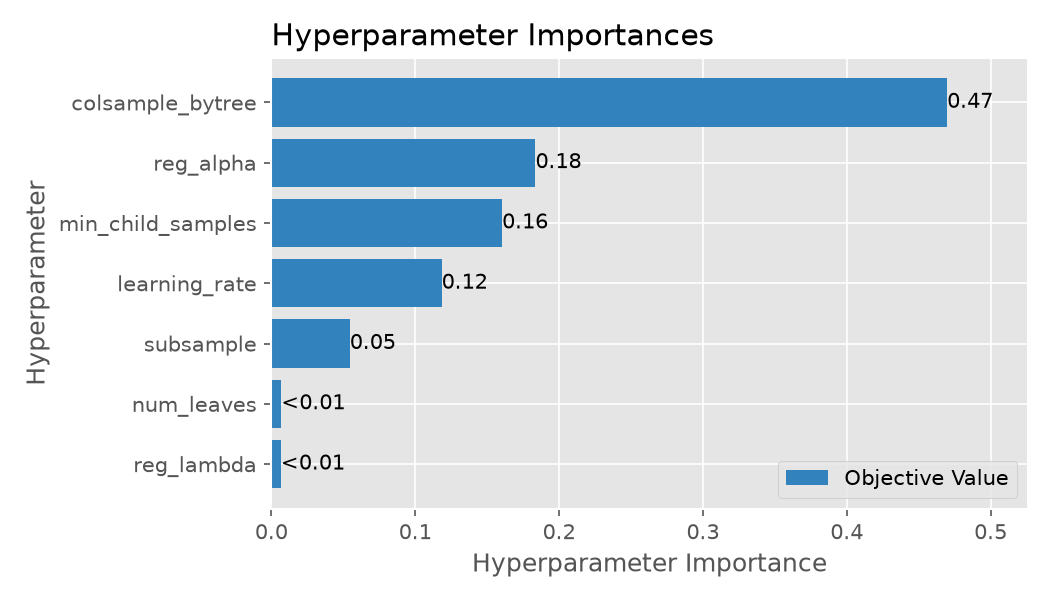

In [8]:
show("optuna_param_importance_v1.png", 700)

## 5. Tuned vs untuned
(a) same 3 folds and every-4th-point training rows for both; (b) both refit on all valid train rows and scored on student_test.

In [9]:
a = pd.read_csv(R / "tuned_vs_untuned_v1.csv").drop(columns=["label_source"])
a

,model,variant,cv_top1,cv_top1_std,cv_macro_f1,cv_logloss,st_top1,st_undirected_top1,st_macro_f1,st_logloss,route_continuity,train_time_s,infer_ms_per_1k,folds,obs_every
0,lgbm,untuned,0.9156,0.0100,0.9497,0.0405,0.9162,0.9515,0.9494,0.0373,0.7926,4.7380,1.4826,3,4
1,lgbm,tuned,0.9186,0.0110,0.9512,0.0404,0.9165,0.9525,0.9509,0.0365,0.8023,16.3818,2.6741,3,4


In [10]:
b = pd.read_csv(R / "tuned_vs_untuned_fulldata_v1.csv")
b

,variant,train_rows,best_iter,st_top1,st_undirected_top1,st_macro_f1,st_logloss,route_continuity,route_breaks,train_time_s,infer_ms_per_1k
0,untuned,2064331,244,0.9159,0.9517,0.9495,0.0386,0.7935,790,14.1627,1.6277
1,tuned,2064331,360,0.9148,0.9526,0.9513,0.0364,0.8022,753,36.3620,3.5620


In [11]:
num = ["cv_top1", "cv_macro_f1", "cv_logloss", "st_top1", "st_macro_f1", "st_logloss", "route_continuity",
       "train_time_s", "infer_ms_per_1k"]
v = a.set_index("variant")[num]
(v.loc["tuned"] - v.loc["untuned"]).to_frame("tuned − untuned (same folds)")

,tuned − untuned (same folds)
cv_top1,0.0030
cv_macro_f1,0.0015
cv_logloss,-0.0001
st_top1,0.0003
st_macro_f1,0.0016
st_logloss,-0.0009
route_continuity,0.0097
train_time_s,11.6437
infer_ms_per_1k,1.1916


## 6. Exported artifact (`artifacts/model_card.json`)

In [12]:
card = json.loads((ROOT / "artifacts" / "model_card.json").read_text())
{k: card[k] for k in ["model", "variant", "label_source", "n_train_rows", "best_iteration", "train_time_s",
                      "infer_ms_per_1k", "train_date", "seed"]}

{'model': 'lgbm (tuned)',
 'variant': 'tuned',
 'label_source': 'train=M3_alignment; student_test=M3_alignment',
 'n_train_rows': 2064331,
 'best_iteration': 360,
 'train_time_s': 39.6784895999881,
 'infer_ms_per_1k': 3.498137130579069,
 'train_date': '2026-11-18T12:55:04',
 'seed': 42}

In [13]:
pd.Series(card["student_test"], name="student_test").to_frame()

,student_test
st_top1,0.9148
st_undirected_top1,0.9526
st_miss_rate,0.0000
st_macro_f1,0.9513
st_precision,0.9150
st_recall,0.9056
st_logloss,0.0364
route_continuity,0.8022
route_breaks,753.0000
